In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

CTY = Path("country_rollout_vs_death.csv")
DRV = Path("covid_derived.parquet")
if not (CTY.exists() and DRV.exists()):
    raise FileNotFoundError(
        "Day 3 needs Day-2 outputs. Run the Day-2 derivation cell first so it emits "
        "country_rollout_vs_death.csv + covid_derived.parquet. Do NOT recompute here — "
        "that would fork the lag/reindex logic and desync your charts."
    )

cty = pd.read_csv(CTY, index_col=0)  # per-country scalars from Day 2
cty["date_50pct"] = pd.to_datetime(cty.get("date_50pct"), errors="coerce")

In [2]:
COLOR_MODE = "continent"  # or "gdp_tertile"
if COLOR_MODE == "continent":
    cty["_hue"] = cty["continent"].fillna("n/a")
    legend_title = "Continent (real column)"
else:
    q = cty["gdp_ppp"].rank(pct=True)
    cty["_hue"] = pd.cut(
        q,
        [-0.01, 0.34, 0.67, 1.01],
        labels=["Lower-third GDP", "Middle-third", "Upper-third"],
    )
    legend_title = "GDP-per-capita tertile WITHIN this set (PPP $; not WB income bands)"

# drop countries that never crossed 50% in-window (honest n, not padded to 7)
plot = cty.dropna(subset=["days_10_to_50", "peak_deaths_pm_post50"]).copy()
n_dropped = len(cty) - len(plot)
print(
    f"[scatter] plotting n={len(plot)} of {len(cty)} countries "
    f"({n_dropped} dropped: no 50%-vax crossing or no post-50 death data)"
)

[scatter] plotting n=6 of 7 countries (1 dropped: no 50%-vax crossing or no post-50 death data)


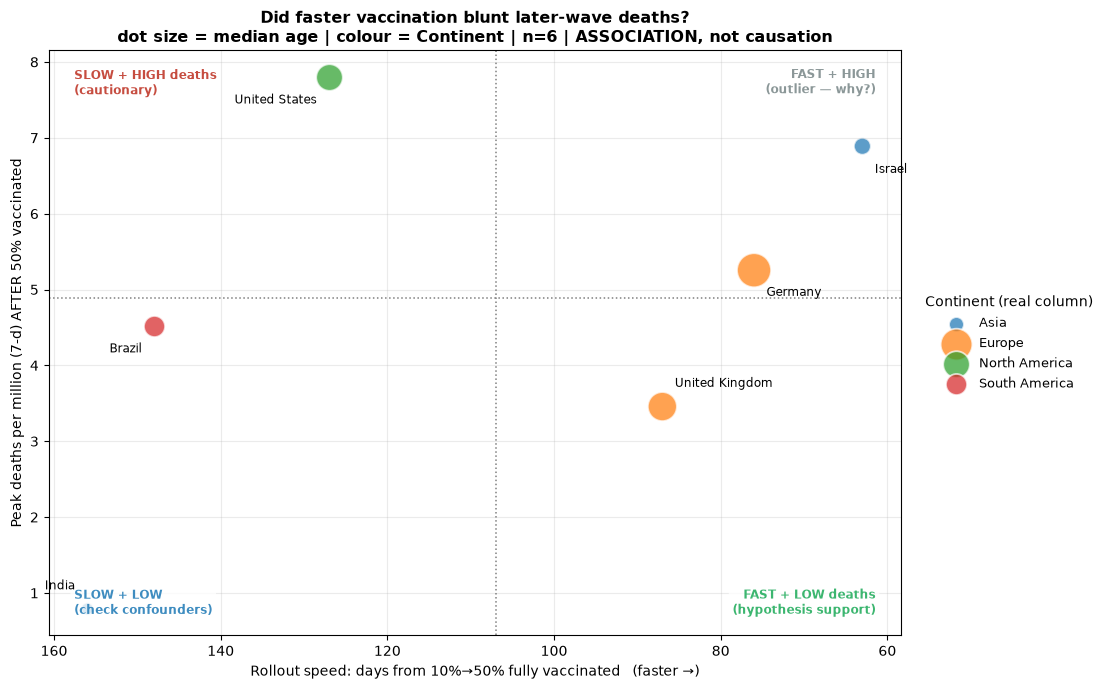

In [6]:
fig, ax = plt.subplots(figsize=(11, 7.6))

# --- colour scatter loop (unchanged logic, kept here so the block is self-contained) ---
cats = sorted(plot["_hue"].astype(str).unique())
cmap = plt.get_cmap("tab10")
for i, c in enumerate(cats):
    g = plot[plot["_hue"].astype(str) == c]
    ax.scatter(
        g["days_10_to_50"],
        g["peak_deaths_pm_post50"],
        s=g["_size"],
        color=cmap(i % 10),
        alpha=0.72,
        edgecolor="white",
        linewidth=1.3,
        label=c,
    )

# --- crosshairs at the column medians ---
med_x, med_y = plot["days_10_to_50"].median(), plot["peak_deaths_pm_post50"].median()
ax.axvline(med_x, color="grey", ls=":", lw=1.1)
ax.axhline(med_y, color="grey", ls=":", lw=1.1)
ax.invert_xaxis()  # fewer days (faster) -> RIGHT

# --- data labels pushed INWARD (away from whichever corner the dot is in) ---
xmin, xmax = plot["days_10_to_50"].min(), plot["days_10_to_50"].max()
ymin, ymax = plot["peak_deaths_pm_post50"].min(), plot["peak_deaths_pm_post50"].max()
for idx, r in plot.iterrows():
    xn = (r["days_10_to_50"] - xmin) / (
        xmax - xmin + 1e-9
    )  # 0=left(slow) .. 1=right(fast)
    yn = (r["peak_deaths_pm_post50"] - ymin) / (ymax - ymin + 1e-9)
    dx = 9 if xn < 0.5 else -9  # horizontal: aim toward centre
    dy = 12 if yn < 0.5 else -12  # vertical:   aim toward centre
    ax.annotate(
        str(r.get("location", idx)),
        (r["days_10_to_50"], r["peak_deaths_pm_post50"]),
        textcoords="offset points",
        xytext=(dx, dy),
        ha="left" if dx > 0 else "right",
        va="bottom" if dy > 0 else "top",
        fontsize=8.5,
        zorder=5,
    )

# --- quadrant captions, mapped CORRECTLY to the inverted x-axis ---
# geometric-left = SLOW (high days); geometric-right = FAST (low days); top = HIGH deaths.
# white bbox so a stray label can never make a caption unreadable.
bb = dict(boxstyle="round,pad=0.32", fc="white", ec="none", alpha=0.78)
for xf, yf, ha, va, txt, col in [
    (0.03, 0.97, "left", "top", "SLOW + HIGH deaths\n(cautionary)", "#C0392B"),
    (0.97, 0.97, "right", "top", "FAST + HIGH\n(outlier — why?)", "#7f8c8d"),
    (0.03, 0.03, "left", "bottom", "SLOW + LOW\n(check confounders)", "#2980B9"),
    (
        0.97,
        0.03,
        "right",
        "bottom",
        "FAST + LOW deaths\n(hypothesis support)",
        "#27AE60",
    ),
]:
    ax.text(
        xf,
        yf,
        txt,
        transform=ax.transAxes,
        ha=ha,
        va=va,
        fontsize=8.5,
        color=col,
        fontweight="bold",
        alpha=0.9,
        bbox=bb,
        zorder=4,
    )

# --- axis / title ---
ax.set_xlabel("Rollout speed: days from 10%→50% fully vaccinated   (faster →)")
ax.set_ylabel("Peak deaths per million (7‑d) AFTER 50% vaccinated")
short_leg = legend_title.split("(")[0].strip()
ax.set_title(
    "Did faster vaccination blunt later‑wave deaths?\n"
    f"dot size = median age | colour = {short_leg} | n={len(plot)} | ASSOCIATION, not causation",
    fontsize=11.5,
    fontweight="bold",
)
ax.grid(alpha=0.25)

# --- legend OUTSIDE the axes (frees all four corners for captions) ---
ax.legend(
    title=legend_title,
    frameon=False,
    loc="center left",
    bbox_to_anchor=(1.015, 0.5),
    fontsize=9,
)

# savefig's tight bbox reserves room for the outside legend; no tight_layout() needed
plt.savefig("focused_scatter_rollout_vs_death.png", dpi=150, bbox_inches="tight")
plt.show()